# DQN on LunarLander-v3

A DQN agent learns to land the lunar module. The notebook reads top to bottom and must run with *Restart & Run All*.

1. Setup and configuration
2. Environment
3. Random baseline
4. DQN components (replay buffer, network, epsilon, agent)
5. Training
6. Results
7. Experiments
8. Conclusion

## 1. Setup

In [ ]:
import os
import random
from collections import Counter

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# The network is tiny: one CPU thread is faster than splitting the work
torch.set_num_threads(1)

RETRAIN = True
MODEL_PATH = "dqn_lunarlander_baseline.pt"
HISTORY_PATH = "dqn_lunarlander_baseline_history.npz"
FINAL_MODEL_PATH = "dqn_lunarlander.pt"

### Configuration

All hyperparameters live in a single dictionary, so an experiment can run with a different configuration without touching the rest of the code.

These values form the **baseline configuration**. They are a first reasonable guess, and some of them are then tested or changed by the experiments in section 7:
- `gamma = 0.99`: the landing happens at the end of a long episode, so the future must count almost as much as the present.
- `learning_rate = 1e-3`, `batch_size = 64`, `hidden_size = 128`: usual values for a small network on a task with 8 inputs. The learning rate is tested in experiment 2.
- `buffer_capacity = 100_000`: a training run plays about 200 000 steps, so the buffer keeps roughly the most recent half of the experiences and the oldest ones are replaced.
- `eps_start = 1.0`, `eps_end = 0.01`, `eps_decay = 0.995`: exponential decay once per episode, tested in experiment 1.
- `target_update_every = 500`: the target network is copied every 500 steps, often enough to follow the network and rarely enough for the target not to move at every update.
- `n_episodes = 600`: enough for the agent to start landing, and short enough to repeat the training for the experiments.

Two entries are not about the learning itself but about how the training is monitored: `eval_every` (an evaluation without exploration every 25 episodes) and `eval_episodes` (10 episodes per evaluation). They decide which weights are kept as the best ones, so they are written here to keep the training reproducible.

Seeds are written down too: `SEED = 42` for the baseline training of section 5, and `SEEDS = [42, 43, 44]` for the experiments of section 7.

In [ ]:
CONFIG = {
    "gamma": 0.99,
    "learning_rate": 1e-3,
    "batch_size": 64,
    "buffer_capacity": 100000,
    "eps_start": 1.0,
    "eps_end": 0.01,
    "eps_decay": 0.995,
    "target_update_every": 500,
    "hidden_size": 128,
    "n_episodes": 600,
    "eval_every": 25,
    "eval_episodes": 10,
}

## 2. Environment

In [3]:
env = gym.make("LunarLander-v3")
state, info = env.reset(seed=SEED)
state_dim = env.observation_space.shape[0]
n_actions = env.action_space.n

print("State dimension:", state_dim)
print("Number of actions:", n_actions)

State dimension: 8
Number of actions: 4


## 3. Random baseline

### Random agent

To know whether an agent learns, we need a point of comparison. The random agent picks one of the 4 actions at random at every step, without looking at the state: this is the score to beat.

Agents are classes that define a `run(*, state)` method: `agent.run(state=state)` returns an action. `run_episode` only knows this interface, so the same function plays the random agent and, later, the DQN agent without exploration.

`RandomAgent` still receives `state`, to respect this interface. It uses `random.randrange`, whose generator is seeded, so the baseline is reproducible.

In [4]:
class RandomAgent:
    def __init__(self, *, n_actions):
        self.n_actions = n_actions

    def run(self, *, state):
        return random.randrange(self.n_actions)


random_agent = RandomAgent(n_actions=n_actions)
print("Random action:", random_agent.run(state=state))

Random action: 0


### Playing an episode

`run_episode(env=env, agent=agent)` plays a full episode: `reset`, then `step` in a loop until the end. It returns the total reward, the number of steps and the reason the episode ended.

`agent` is any object with a `run(state=...)` method that returns an action: `RandomAgent` here, and later `DQNAgent` played without exploration. The same function therefore serves every agent.

The loop stops when `terminated` or `truncated` is true, but the two stay separate variables because they do not mean the same thing:
- `terminated`: the episode is really over. Three possible causes: `crash` (the lander body touches the ground), `out_of_viewport` (`abs(x) >= 1`), or `at_rest` (the lander is down and no longer moves).
- `truncated`: the episode was cut at the maximum number of steps, the lander could have kept going.

The crash is tested first: a crash that throws the lander off screen counts as a crash.

`evaluate`, defined right after, replays an agent over several episodes and summarizes its scores. It is first used on the random agent.

In [5]:
def end_reason(*, env, next_state, terminated):
    if not terminated:
        return "truncated"
    if env.unwrapped.game_over:
        return "crash"
    if abs(next_state[0]) >= 1.0:
        return "out_of_viewport"
    return "at_rest"


def run_episode(*, env, agent, seed=None):
    state, _ = env.reset(seed=seed)
    total_reward = 0.0
    steps = 0

    while True:
        action = agent.run(state=state)
        next_state, reward, terminated, truncated, _ = env.step(action)

        total_reward += reward
        steps += 1

        if terminated or truncated:
            reason = end_reason(env=env, next_state=next_state, terminated=terminated)
            return total_reward, steps, reason

        state = next_state

### Evaluating an agent

`evaluate(env=env, agent=agent, n_episodes=N, name=...)` plays `N` episodes with `run_episode`, prints the mean score, the standard deviation, the mean number of steps, the breakdown of end reasons and the number of episodes above the threshold of 200 (`SOLVED`), then returns the list of rewards. The same function evaluates the random baseline and the DQN agent, with exactly the same measures.

In [6]:
N_EVAL = 100
SOLVED = 200


def evaluate(*, env, agent, n_episodes, name="", verbose=True):
    rewards, steps_list, reasons = [], [], []
    for _ in range(n_episodes):
        total_reward, steps, reason = run_episode(env=env, agent=agent)
        rewards.append(total_reward)
        steps_list.append(steps)
        reasons.append(reason)

    if verbose:
        print(f"{name} over {n_episodes} episodes")
        print(f"Mean reward: {np.mean(rewards):.1f}")
        print(f"Std reward:  {np.std(rewards):.1f}")
        print(f"Mean steps:  {np.mean(steps_list):.1f}")
        print("End reasons:", dict(Counter(reasons)))
        print(f"Episodes with reward >= {SOLVED}: {sum(r >= SOLVED for r in rewards)}/{n_episodes}")
    return rewards

Random agent over 100 episodes
Mean reward: -173.4
Std reward:  110.0
Mean steps:  88.2
End reasons: {'crash': 93, 'out_of_viewport': 7}
Episodes with reward >= 200: 0/100


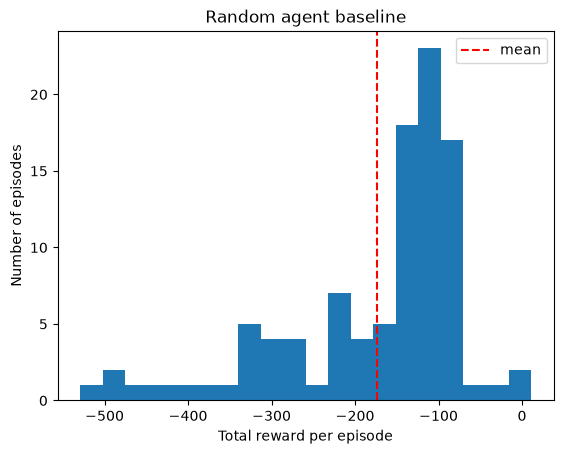

In [7]:
baseline_rewards = evaluate(env=env, agent=random_agent, n_episodes=N_EVAL, name="Random agent")

plt.hist(baseline_rewards, bins=20)
plt.axvline(np.mean(baseline_rewards), color="red", linestyle="--", label="mean")
plt.xlabel("Total reward per episode")
plt.ylabel("Number of episodes")
plt.title("Random agent baseline")
plt.legend()
plt.show()

#### Analysis: random baseline

- **Mean reward: -173.4** (std 110), and **0 episode out of 100** reaches the 200 threshold. This is the score to beat.
- Episodes are **short** (88 steps on average): the random agent does not hover, it falls and hits the ground. The end reasons confirm it: 93 `crash` and 7 `out_of_viewport`, none `at_rest` and none `truncated`.
- The histogram is therefore concentrated on negative values, with a tail towards very bad scores. Nothing comes close to a successful landing.
- Consequence for the rest of the notebook: any agent that lands even a few times will stand out clearly from this distribution.

## 4. DQN components

### Replay buffer

Consecutive steps of an episode look very much alike, so learning in order is unstable. The buffer keeps the latest experiences `(state, action, reward, next_state, done)` up to a fixed capacity (the oldest ones are replaced), and `sample` draws a random batch from it as 5 tensors.

We will store `done = terminated` only: a `truncated` episode is not really over, so its future must still be taken into account in the target.

In [8]:
class ReplayBuffer:
    def __init__(self, *, capacity):
        self.capacity = capacity
        self.buffer = []    

    def __len__(self):
        return len(self.buffer)
    
    def push(self, *, state, action, reward, next_state, done):
        if len(self.buffer) >= self.capacity:
            self.buffer.pop(0)
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, *, batch_size):
        if batch_size > len(self.buffer):
            raise ValueError("Batch size exceeds buffer size.")
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = [], [], [], [], []
        for exp in batch:
            states.append(exp[0])
            actions.append(exp[1])
            rewards.append(exp[2])
            next_states.append(exp[3])
            dones.append(exp[4])

        states = torch.tensor(np.array(states), dtype=torch.float32)
        actions = torch.tensor(actions, dtype=torch.long)
        rewards = torch.tensor(rewards, dtype=torch.float32)
        next_states = torch.tensor(np.array(next_states), dtype=torch.float32)
        dones = torch.tensor(dones, dtype=torch.float32)
        return states, actions, rewards, next_states, dones

### Q-network (neural network)

The network takes the lander state (8 numbers) and returns one Q-value per action (4 numbers). The agent will play the action with the highest Q-value.

```
state (8)  ->  Linear(8, 128)  ->  ReLU  ->  Linear(128, 128)  ->  ReLU  ->  Linear(128, 4)  ->  Q-values (4)
```

- **`Linear`** mixes the input numbers with adjustable weights. These weights are what training adjusts.
- **`ReLU`** sets negative values to 0. Without it, chaining several `Linear` layers would be equivalent to a single `Linear`: the network could only learn very simple relations.
- No `ReLU` at the output: a Q-value can be negative, and we want to read it as is.
- The input size (`state_dim`) and output size (`n_actions`) are read from the environment. The size of the hidden layers (128) is a hyperparameter.

#### Why a class with `forward`, and why we write `network(x)`

`QNetwork` inherits from `nn.Module`, the base class of PyTorch networks.

- In `__init__`, we **build** the layers, once. Their weights live in the object and are modified by training.
- In `forward`, we describe **the computation**: in which order `x` goes through the layers.
- We do not call `network.forward(x)` but `network(x)`. In Python, an object whose class defines `__call__` can be called like a function. `nn.Module` defines this method, and it calls our `forward` while adding some internal PyTorch operations around it (hooks, tracking of computations).

```
network(x)  ->  nn.Module.__call__  ->  QNetwork.forward(x)  ->  self.network(x)  ->  Q-values
```

If we forget to define `forward`, `network(x)` raises a `NotImplementedError`.

Expected shapes: a single state `(8,)` gives `(4,)`, a batch of 32 states `(32, 8)` gives `(32, 4)`. The batch is used for learning, which processes several experiences at once.

In [9]:
from torch import nn


class QNetwork(nn.Module):
    def __init__(self, *, state_dim, n_actions, hidden):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions)
        )
    
    def forward(self, x):
        return self.network(x)
    
network = QNetwork(state_dim=state_dim, n_actions=n_actions, hidden=CONFIG["hidden_size"])
print(network(torch.zeros((1, state_dim))))

tensor([[ 0.0489, -0.0024,  0.0125,  0.1445]], grad_fn=<AddmmBackward0>)


### Epsilon decay

With probability epsilon, the agent plays a random action (exploration). Otherwise it plays the action with the highest Q-value (exploitation). Epsilon starts high and decays, and is 0 during evaluation: the agent no longer explores.

`epsilon_at` computes epsilon **once per episode** (`eps_start * eps_decay ** episode`, with a floor at `eps_end`). The choice of the action itself (`choose_action`) is a method of `DQNAgent`, defined further down.

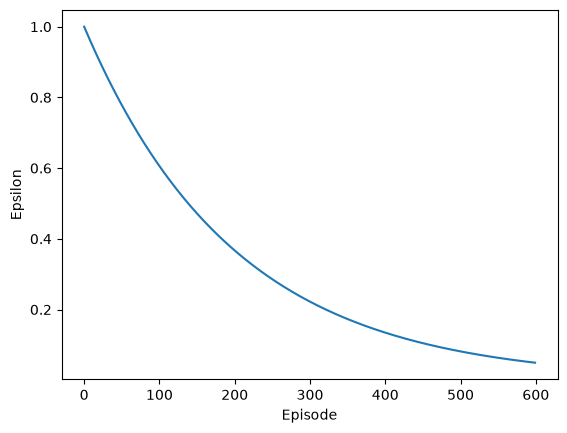

In [10]:

def epsilon_at(*, episode, config):
    eps = config["eps_start"] * config["eps_decay"] ** episode
    return max(config["eps_end"], eps)

epsilons = []
for episode in range(CONFIG["n_episodes"]):
    epsilons.append(epsilon_at(episode=episode, config=CONFIG))

plt.plot(epsilons)
plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.show()

#### Analysis: epsilon decay

- The curve is **exponential** (`0.995 ** episode`): it drops fast at the start, then flattens. Epsilon is 0.61 at episode 100, 0.37 at 200, 0.22 at 300, 0.13 at 400, 0.08 at 500 and about 0.05 at the last episode.
- Epsilon only goes below 0.1 around episode 460: **more than three quarters of the training is done with at least 10% random actions**. The agent explores a lot, which is also why the training rewards underestimate its real level.
- The floor `eps_end = 0.01` is **never reached** within 600 episodes (it would need about 920). The agent still plays about 5% random actions at the end of training, hence the experiment of section 7 with a faster decay.

### The DQN agent

`DQNAgent` groups what belongs to a single agent: the network, the target network, the optimizer and the replay buffer. Creating a new agent with a different `config` rebuilds everything cleanly, which will be useful for the experiments in section 7.

| Method | Role |
|---|---|
| `choose_action(state, epsilon)` | epsilon-greedy action |
| `run(state)` | greedy action (epsilon = 0), used by `run_episode` |
| `remember(...)` | stores an experience in the buffer (`done = terminated` only) |
| `learn()` | one learning step on a randomly drawn batch, returns the loss (or `None` if the buffer is too small) |
| `update_target()` | copies `network` into `target_network` |
| `train(env)` | training loop, returns a `history` dictionary (see below) |
| `save(path)` / `load(path)` | saves and loads the weights of `network` |

In `learn`, the Bellman target is `reward + gamma * max Q_target(next_state) * (1 - done)`. It is computed under `no_grad`: it is a constant, only `network` is trained. The `target_network` is only copied every `target_update_every` steps, so that the target does not move at every update.

The step counter in `train` is global (it does not restart from 0 at each episode), because the target network copy is counted in total steps.

#### What `train` records and keeps

- For each episode, `history` stores the reward, the number of steps, the mean loss, epsilon and the reason the episode ended (`end_reason`, the same function as in `run_episode`).
- Every `eval_every` episodes, the agent is evaluated **without exploration** on `eval_episodes` episodes. The episode number and the mean score go into `history` (`eval_episodes`, `eval_means`).
- The weights with the best evaluation score are copied (`clone`, otherwise the copy would follow the weights as they keep changing). At the end of the training they are loaded back, so the agent returned by `train` is the best one seen and not necessarily the last one.
- An evaluation of `eval_episodes` episodes is a noisy estimate, so the "best" weights can be partly luck. The final evaluation over 100 episodes (section 6) remains the reference measure.

In [11]:
class DQNAgent:
    def __init__(self, *, state_dim, n_actions, config):
        self.n_actions = n_actions
        self.config = config
        self.network = QNetwork(state_dim=state_dim, n_actions=n_actions, hidden=config["hidden_size"])
        self.target_network = QNetwork(state_dim=state_dim, n_actions=n_actions, hidden=config["hidden_size"])
        self.update_target()
        self.optimizer = torch.optim.Adam(self.network.parameters(), lr=config["learning_rate"])
        self.buffer = ReplayBuffer(capacity=config["buffer_capacity"])

    def run(self, *, state):
        return self.choose_action(state=state, epsilon=0.0)

    def choose_action(self, *, state, epsilon):
        if random.random() < epsilon:
            return random.randrange(self.n_actions)
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            q_values = self.network(state_tensor)
        return torch.argmax(q_values).item()

    def remember(self, *, state, action, reward, next_state, done):
        self.buffer.push(state=state, action=action, reward=reward, next_state=next_state, done=done)

    def learn(self):
        if len(self.buffer) < self.config["batch_size"]:
            return None

        # 1. A batch of past experiences, drawn at random
        states, actions, rewards, next_states, dones = self.buffer.sample(batch_size=self.config["batch_size"])

        # 2. Prediction: what the network believes, for the action actually played
        q_values = self.network(states)
        predicted = q_values.gather(1, actions.unsqueeze(1)).squeeze(1)

        # 3. Bellman target: reward received + estimated value of the future
        #    no_grad: the target is a constant, we do not train the target_network
        with torch.no_grad():
            next_q_values = self.target_network(next_states)
            best_next = next_q_values.max(dim=1).values
            targets = rewards + self.config["gamma"] * best_next * (1 - dones)

        # 4. Gap between prediction and target
        loss = ((predicted - targets) ** 2).mean()

        # 5. Update the weights of network only
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.item()

    def update_target(self):
        self.target_network.load_state_dict(self.network.state_dict())

    def train(self, *, env, verbose=True):
        history = {"rewards": [], "steps": [], "losses": [], "epsilons": [], "reasons": [], "eval_episodes": [], "eval_means": []}
        total_steps = 0
        best_eval = -np.inf
        best_weights = None

        for episode in range(self.config["n_episodes"]):
            state, _ = env.reset()
            epsilon = epsilon_at(episode=episode, config=self.config)
            episode_reward = 0
            episode_steps = 0
            episode_losses = []

            while True:
                action = self.choose_action(state=state, epsilon=epsilon)
                next_state, reward, terminated, truncated, _ = env.step(action)

                self.remember(state=state, action=action, reward=reward, next_state=next_state, done=terminated)

                loss = self.learn()
                if loss is not None:
                    episode_losses.append(loss)

                total_steps += 1
                if total_steps > self.config["target_update_every"]:
                    self.update_target()        
                    total_steps = 0

                episode_reward += reward
                episode_steps += 1
                if terminated or truncated:
                    reason = end_reason(env=env, next_state=next_state, terminated=terminated)
                    break
                state = next_state

            history["rewards"].append(episode_reward)
            history["steps"].append(episode_steps)
            history["losses"].append(np.mean(episode_losses) if episode_losses else np.nan)
            history["epsilons"].append(epsilon)
            history["reasons"].append(reason)
            if verbose:
                print(f"Episode {episode + 1}/{self.config['n_episodes']}, Reward: {episode_reward:.2f}, Steps: {episode_steps}, End: {reason}, Epsilon: {epsilon:.3f}")

            if (episode + 1) % self.config["eval_every"] == 0:
                eval_rewards = evaluate(env=env, agent=self, n_episodes=self.config["eval_episodes"], verbose=False)
                eval_mean = np.mean(eval_rewards)
                history["eval_episodes"].append(episode + 1)
                history["eval_means"].append(eval_mean)
                if eval_mean > best_eval:
                    best_eval = eval_mean
                    best_weights = {name: value.clone() for name, value in self.network.state_dict().items()}
                if verbose:
                    n = self.config["eval_every"]
                    print(f"--- Episodes {episode + 2 - n}-{episode + 1}: mean reward {np.mean(history['rewards'][-n:]):.1f}, mean steps {np.mean(history['steps'][-n:]):.0f}")
                    print(f"--- Evaluation: mean {eval_mean:.1f} (best {best_eval:.1f})")

        if best_weights is not None:
            self.network.load_state_dict(best_weights)
            self.update_target()

        return history

    def save(self, *, path):
        torch.save(self.network.state_dict(), path)

    def load(self, *, path):
        self.network.load_state_dict(torch.load(path))
        self.update_target()

## 5. Training

We create the agent from `CONFIG`, the **baseline** configuration. Then, depending on the `RETRAIN` flag at the top of the notebook, the next cell either trains it and saves it, or loads the model already saved.

- `RETRAIN = True` (the value in this notebook): the agent is trained again and the saved model is overwritten.
- `RETRAIN = False`: if `MODEL_PATH` exists, its weights are loaded and nothing is trained, so *Run All* is fast. If the file does not exist, the agent is trained anyway.
- `agent.train(env=env)` plays `n_episodes` episodes with exploration (decaying epsilon) and learns at every step. For each episode it prints the reward, the number of steps and the end reason, every `eval_every` episodes it also prints a summary and the result of an evaluation without exploration, and it keeps the best weights. It returns the `history` of the training: reward, number of steps, mean loss, epsilon and end reason of each episode, plus the evaluation scores (used in section 6).
- `agent.save(path=...)` writes the network weights to a file (the best ones found during the training), and the training history is saved next to it (`HISTORY_PATH`) so the learning curves of section 6 can still be drawn after a load. `agent.load(path=...)` reloads the weights.

This section saves the **baseline** model (`dqn_lunarlander_baseline.pt`). The final model, trained with the configuration chosen in section 7, is saved as `dqn_lunarlander.pt` (`FINAL_MODEL_PATH`).

In [12]:
agent = DQNAgent(state_dim=state_dim, n_actions=n_actions, config=CONFIG)

if RETRAIN or not os.path.exists(MODEL_PATH):
    history = agent.train(env=env)
    agent.save(path=MODEL_PATH)
    np.savez(HISTORY_PATH, **history)
else:
    agent.load(path=MODEL_PATH)
    history = dict(np.load(HISTORY_PATH)) if os.path.exists(HISTORY_PATH) else None
    print(f"Model loaded from {MODEL_PATH}, no training (set RETRAIN = True to train again).")

Episode 1/600, Reward: -364.15, Steps: 100, End: out_of_viewport, Epsilon: 1.000
Episode 2/600, Reward: -71.78, Steps: 64, End: crash, Epsilon: 0.995
Episode 3/600, Reward: -158.32, Steps: 63, End: crash, Epsilon: 0.990
Episode 4/600, Reward: -114.57, Steps: 74, End: crash, Epsilon: 0.985
Episode 5/600, Reward: -407.12, Steps: 81, End: crash, Epsilon: 0.980
Episode 6/600, Reward: -95.95, Steps: 58, End: crash, Epsilon: 0.975
Episode 7/600, Reward: 44.81, Steps: 103, End: crash, Epsilon: 0.970
Episode 8/600, Reward: -189.61, Steps: 98, End: crash, Epsilon: 0.966
Episode 9/600, Reward: -130.17, Steps: 112, End: crash, Epsilon: 0.961
Episode 10/600, Reward: -108.58, Steps: 89, End: crash, Epsilon: 0.956
Episode 11/600, Reward: -79.02, Steps: 84, End: crash, Epsilon: 0.951
Episode 12/600, Reward: -123.71, Steps: 62, End: crash, Epsilon: 0.946
Episode 13/600, Reward: -118.52, Steps: 81, End: crash, Epsilon: 0.942
Episode 14/600, Reward: -165.59, Steps: 67, End: crash, Epsilon: 0.937
Episode

## 6. Results

Two different measures, not to be confused:
- the **training rewards** (learning curve) are obtained with exploration: they are noisy and underestimate the real level of the agent,
- the **evaluation** replays the agent without exploration (`agent.run`, so epsilon = 0): this is the real score, comparable to the random baseline.

The agent evaluated in this section is the **best checkpoint** kept by `train` (the weights with the best evaluation score during the training, see section 4), not necessarily the weights of the last episode. It is chosen on a short evaluation (`eval_episodes` episodes) and then evaluated again on 100 new episodes: the final score is measured on episodes that did not take part in the choice, so the choice does not inflate it.

### Learning curves

Four curves from the training `history`: the reward of each episode with its moving average over 100 episodes (the threshold of 200 is the one from which LunarLander is considered solved), the episode length, the loss (mean per episode) and epsilon. They show the training as it really happened, including its bad moments. The green points are the periodic evaluations without exploration, the ones used to pick the best checkpoint.

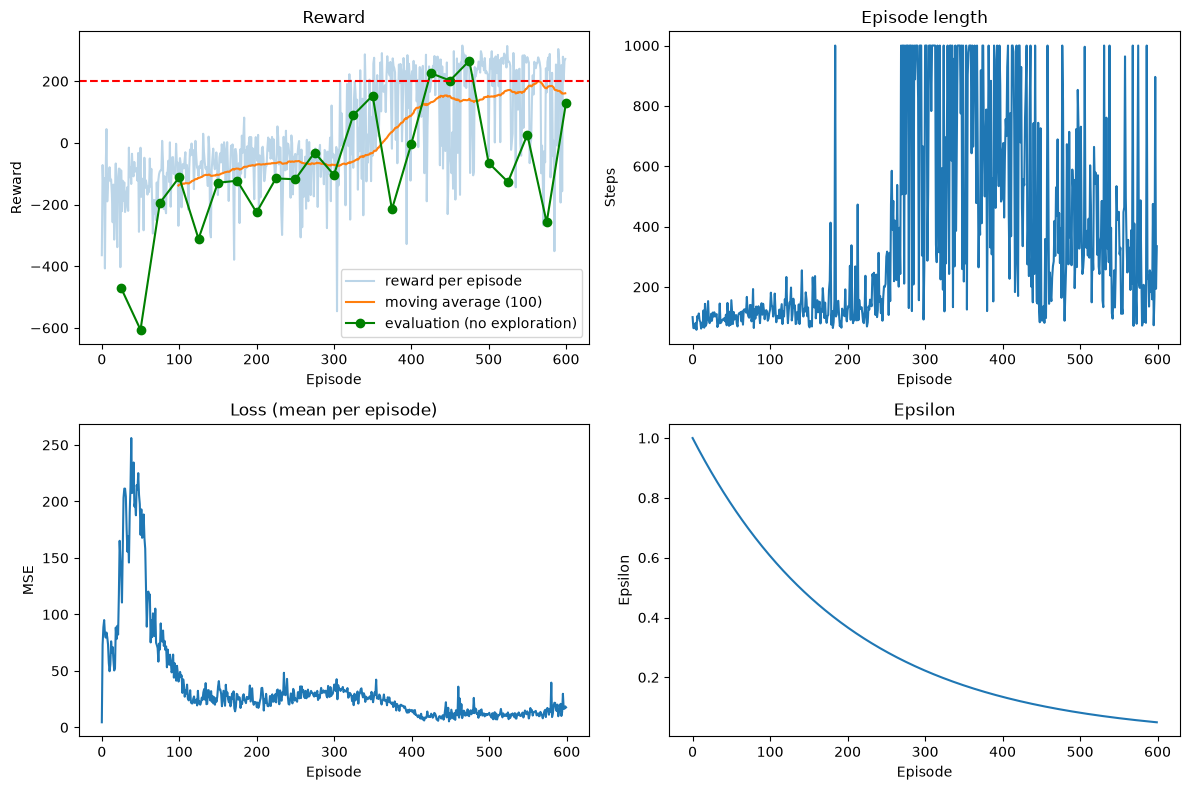

End reasons during training: {'out_of_viewport': 14, 'crash': 333, 'truncated': 73, 'at_rest': 180}


In [13]:
WINDOW = 100

if history is None:
    print("No learning curves: the model was loaded and no saved training history was found.")
else:
    rewards = history["rewards"]
    moving_avg = np.convolve(rewards, np.ones(WINDOW) / WINDOW, mode="valid")

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    axes[0, 0].plot(rewards, alpha=0.3, label="reward per episode")
    axes[0, 0].plot(np.arange(WINDOW - 1, len(rewards)), moving_avg, label=f"moving average ({WINDOW})")
    axes[0, 0].plot(history["eval_episodes"], history["eval_means"], "o-", color="green", label="evaluation (no exploration)")
    axes[0, 0].axhline(SOLVED, color="red", linestyle="--")
    axes[0, 0].set_title("Reward")
    axes[0, 0].set_ylabel("Reward")
    axes[0, 0].legend()

    axes[0, 1].plot(history["steps"])
    axes[0, 1].set_title("Episode length")
    axes[0, 1].set_ylabel("Steps")

    axes[1, 0].plot(history["losses"])
    axes[1, 0].set_title("Loss (mean per episode)")
    axes[1, 0].set_ylabel("MSE")

    axes[1, 1].plot(history["epsilons"])
    axes[1, 1].set_title("Epsilon")
    axes[1, 1].set_ylabel("Epsilon")

    for ax in axes.flat:
        ax.set_xlabel("Episode")
    plt.tight_layout()
    plt.show()

    print("End reasons during training:", dict(Counter(history["reasons"])))

#### Analysis: learning curves

- **The learning is slow and not regular.** The moving average of the training reward is about -138 at episode 100, still -71 at episodes 200 and 300, then 87 at episode 400, 152 at episode 500 and 161 at the end. Its maximum is 199 (episode 566): with exploration still at about 5%, the training reward never reaches the threshold of 200.
- **The evaluations without exploration are very unstable.** They go from -606 (episode 50) to +266 (episode 475), and only 3 evaluations out of 24 are above 200 (episodes 425, 450 and 475). A good policy is not kept: the evaluation falls back to -65 at episode 500 and -258 at episode 575, then ends at 130 at episode 600. The last weights are therefore much worse than the best ones, which is exactly why `train` keeps the best checkpoint (here the one of episode 475).
- **The agent first learns to hover, then to land.** The episode length goes from about 103 steps (first 100 episodes) to 358 (last 100 episodes). 73 episodes reach the limit of 1000 steps (`truncated`), and they are concentrated between episodes 200 and 400 (18 then 38 per block of 100), then fall to 5 in the last 100 episodes. The agent first avoids crashing by staying in the air, and only later learns to put the lander down.
- **The loss does not tell if the agent improves.** It is about 57 at episode 10, 41 at episode 100, 33 at episode 300 and 18 at the end, with a peak of 256 at episode 38. It decreases slowly, but it is not a measure of quality: the target moves with the network, and the evaluation keeps oscillating while the loss goes down.
- **End reasons during training:** 333 `crash`, 180 `at_rest`, 73 `truncated` and 14 `out_of_viewport`. The proportion changes a lot over time: in the last 100 episodes there are 69 `at_rest` against 25 `crash`, 5 `truncated` and 1 `out_of_viewport`.

### Evaluation without exploration

100 episodes with `agent.run`, same measures as for the random baseline of section 3.

In [14]:
eval_rewards = evaluate(env=env, agent=agent, n_episodes=N_EVAL, name="DQN agent")

DQN agent over 100 episodes
Mean reward: 221.0
Std reward:  113.2
Mean steps:  331.4
End reasons: {'at_rest': 89, 'truncated': 5, 'crash': 4, 'out_of_viewport': 2}
Episodes with reward >= 200: 82/100


### Comparison with the baseline

Histogram of the scores of the DQN agent and of the random agent, with their means.

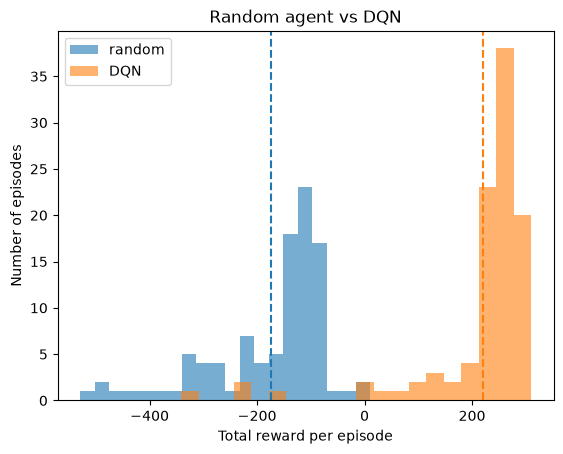

In [15]:
plt.hist(baseline_rewards, bins=20, alpha=0.6, label="random")
plt.hist(eval_rewards, bins=20, alpha=0.6, label="DQN")
plt.axvline(np.mean(baseline_rewards), color="C0", linestyle="--")
plt.axvline(np.mean(eval_rewards), color="C1", linestyle="--")
plt.xlabel("Total reward per episode")
plt.ylabel("Number of episodes")
plt.title("Random agent vs DQN")
plt.legend()
plt.show()

#### Analysis: evaluation of the baseline agent

- **The agent clearly beats the random baseline:** a mean reward of **221.0** (std 113.2) against -173.4 (std 110.0), and **82 episodes out of 100** above 200 against 0.
- **It lands most of the time.** The end reasons are 89 `at_rest`, 5 `truncated`, 4 `crash` and 2 `out_of_viewport`. The episodes last 331 steps on average, against 88 for the random agent: the agent takes time to land instead of falling.
- **The spread is large** (std 113). 18 episodes are below 200: 11 do not end with a landing (5 hovering until the limit, 4 crashes, 2 exits) and at least 7 end at rest with a score under 200, so a landing is not always a good landing.
- **The choice of the checkpoint is slightly optimistic, but the measure is not.** The best checkpoint scored 266.4 on the 10 episodes used to choose it, and 221.0 on 100 new episodes: the difference (about 45 points) is the effect of choosing the best of 24 noisy evaluations. The 221.0 is the honest number, because those 100 episodes played no role in the choice.
- **This is one training with one seed.** In section 7, the same configuration trained with the seeds 42, 43 and 44 gives 244.9, 225.0 and 215.3 (mean 228.4), which is consistent with 221.0. Seed 42 does not give exactly the same agent as here, because the two trainings do not consume the random numbers in the same order.

### Visualization

To watch the agent play, we create a **second environment** with `render_mode="human"` (pygame window). The training environment stays without rendering, which keeps it fast. The agent plays without exploration (`agent.run`) through `run_episode`, as for the evaluation.

To replay a saved model without training again: create a `DQNAgent`, then `agent.load(path="dqn_lunarlander.pt")`.

In [16]:
# N_WATCH = 10

# watch_env = gym.make("LunarLander-v3", render_mode="human")
# for _ in range(N_WATCH):
#     total_reward, steps, reason = run_episode(env=watch_env, agent=agent)
#     print(f"reward = {total_reward:.1f}, steps = {steps}, end = {reason}")
# watch_env.close()

## 7. Experiments

We try to improve the baseline configuration with two experiments, one after the other: experiment 2 starts from the best configuration of experiment 1. Rules, so that the trials are comparable:
- inside an experiment, change **one** parameter at a time, the rest stays at the value of the base configuration (`CONFIG` for experiment 1, the winner of experiment 1 for experiment 2),
- same training budget (`n_episodes`) and the same list of seeds (`SEEDS`) for every trial,
- the base configuration is part of each experiment (`(ref)`), so each trial is compared with a reference obtained under the same conditions,
- two measures: the mean score over 100 episodes without exploration (the final level) and the episode at which the moving average reaches 200 (the learning speed).

A DQN training is very variable: with the same configuration, two seeds can give very different agents. Each configuration is therefore trained once **per seed** and the results are summarized across seeds: the evaluation score of each seed, their mean with the spread between seeds, and the number of seeds that reach a moving average of 200. A gap between two configurations only means something if it is larger than the spread between seeds.

To keep the notebook readable, the machinery is written once in the next cell. Each experiment then boils down to a small dictionary `{name: modified parameters}` and two calls. A cache (`experiment_cache`) remembers each `(configuration, seed)` that has been trained: the reference of experiment 2 is the winner of experiment 1, so it is not trained twice.

Each trial redoes a full training run, which takes several minutes per configuration and per seed. The curves show the mean of the moving average over the seeds, with the band between the best and the worst seed.

In [17]:
SEEDS = [42, 43, 44]
experiment_cache = {}


def run_experiment(*, config, seed, save_path=None):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    exp_env = gym.make("LunarLander-v3")
    exp_env.reset(seed=seed)

    exp_agent = DQNAgent(state_dim=state_dim, n_actions=n_actions, config=config)
    train_rewards = exp_agent.train(env=exp_env, verbose=False)["rewards"]
    if save_path is not None:
        exp_agent.save(path=save_path)
    eval_rewards = evaluate(env=exp_env, agent=exp_agent, n_episodes=N_EVAL, verbose=False)
    exp_env.close()

    moving_avg = np.convolve(train_rewards, np.ones(WINDOW) / WINDOW, mode="valid")

    solved_at = None
    for i, value in enumerate(moving_avg):
        if value >= SOLVED:
            solved_at = i + WINDOW
            break

    return {
        "moving_avg": moving_avg,
        "eval_mean": float(np.mean(eval_rewards)),
        "eval_std": float(np.std(eval_rewards)),
        "solved_at": solved_at,
    }


def run_experiments(*, experiments, seeds, base=None, save_paths=None):
    base = CONFIG if base is None else base
    save_paths = save_paths or {}
    results = {}
    for name, changes in experiments.items():
        config = base.copy()
        config.update(changes)
        runs = []
        for i, seed in enumerate(seeds):
            key = (tuple(sorted(config.items())), seed)
            if key in experiment_cache:
                print(name, "seed", seed, "reused")
            else:
                save_path = save_paths.get(name) if i == 0 else None
                experiment_cache[key] = run_experiment(config=config, seed=seed, save_path=save_path)
                print(name, "seed", seed, "done")
            runs.append(experiment_cache[key])
        results[name] = runs
    return results


def show_results(*, results):
    for name, runs in results.items():
        eval_means = [run["eval_mean"] for run in runs]
        eval_stds = [run["eval_std"] for run in runs]
        solved = [run["solved_at"] for run in runs]
        n_solved = sum(s is not None for s in solved)
        print(
            name,
            "| eval mean per seed:", [round(m, 1) for m in eval_means],
            "| mean:", round(np.mean(eval_means), 1), "+/-", round(np.std(eval_means), 1),
            "| mean eval std:", round(np.mean(eval_stds), 1),
            "| solved:", f"{n_solved}/{len(runs)}", "at", solved,
        )

    for name, runs in results.items():
        curves = np.array([run["moving_avg"] for run in runs])
        x = np.arange(WINDOW - 1, WINDOW - 1 + curves.shape[1])
        line, = plt.plot(x, curves.mean(axis=0), label=name)
        plt.fill_between(x, curves.min(axis=0), curves.max(axis=0), color=line.get_color(), alpha=0.15)
    plt.axhline(SOLVED, color="red", linestyle="--")
    plt.xlabel("Episode")
    plt.ylabel(f"Reward (moving average {WINDOW})")
    plt.legend()
    plt.show()

### Experiment 1: epsilon decay speed (`eps_decay`)

With `eps_decay = 0.995`, epsilon is still 0.05 at episode 600: the agent plays 5% random actions until the end, and in the training of section 5 the moving average gets close to 200 only at the very end (199 at episode 566). A faster decay leaves more episodes to exploitation. We test 0.99 and 0.98 (epsilon drops below 0.05 around episode 300 and 150).

The trial `eps_decay=0.98` also saves the model of seed 42 as `dqn_lunarlander.pt`: it is the final model, because the winner of this experiment keeps the baseline learning rate (see the analysis of experiment 2).

In [ ]:
experiments_eps_decay = {
    "eps_decay=0.995 (ref)": {},
    "eps_decay=0.99": {"eps_decay": 0.99},
    "eps_decay=0.98": {"eps_decay": 0.98},
}

results_eps_decay = run_experiments(
    experiments=experiments_eps_decay,
    seeds=SEEDS,
    save_paths={"eps_decay=0.98": FINAL_MODEL_PATH},
)
show_results(results=results_eps_decay)

#### Analysis: experiment 1 (`eps_decay`)

| config | eval mean per seed (42, 43, 44) | mean ± spread between seeds | mean eval std | solved at (42, 43, 44) |
|---|---|---|---|---|
| 0.995 (ref) | 244.9, 225.0, 215.3 | 228.4 ± 12.4 | 81.7 | 531, 523, never |
| 0.99 | -127.8, 265.4, 231.3 | 123.0 ± 177.9 | 50.0 | never, 283, 466 |
| **0.98** | 249.8, 263.3, 240.0 | **251.0 ± 9.6** | 59.3 | 315, 328, 459 |

**What the results show**
- **0.98 is the best configuration.** It has the best mean (251.0), the smallest spread between seeds (9.6), it reaches a moving average of 200 on the 3 seeds, and it gets there much earlier than the reference (episodes 315, 328 and 459 against 531 and 523 for the reference, which fails on the third seed). Its mean is 23 points above the reference, about twice the spread between seeds.
- **A faster decay speeds up learning.** With 0.98, epsilon is below 0.1 from episode 115, so the agent spends most of the training exploiting what it has learned. With 0.995 it explores until the end, which is why the reference reaches 200 so late.
- **0.99 is unstable, not slow.** Two seeds are good (265.4 is even the best score of the experiment, and 231.3), but the third one ends at -127.8, and its moving average never reaches 200: even the best checkpoint of this training is bad. This explains the huge spread (177.9). We did not investigate the cause, so we cannot say why one seed fails and not the others: with 3 seeds, it is a warning more than an explanation.
- **The std inside an evaluation also goes down with 0.98** (59.3 against 81.7 for the reference): the landings are more regular.

**A result that reversed.** A first version of this experiment, with a single seed, ranked the configurations differently: the reference was the best on the final score and 0.99 the worst (scores around 214, 115 and 187). Over three seeds the ranking changes. A single seed was not enough to decide, which is why every experiment of this notebook uses three seeds.

**Decision and limits**
- We keep `eps_decay = 0.98` as the base of experiment 2.
- Three seeds is still few: the 23 points between 0.98 and the reference are convincing mostly because 0.98 also reaches 200 earlier on every seed. The result of 0.99 shows that one bad seed is enough to change a mean by more than 100 points.
- The `eps_decay` experiment was run with the other hyperparameters at their baseline values, so its conclusion could change with other values.

### Experiment 2: learning rate (`learning_rate`)

This experiment starts from the winner of experiment 1 (`eps_decay = 0.98`, written by hand in the `base` argument of the next cell). The learning rate sets the size of each weight update: with `learning_rate = 1e-3`, a single noisy batch can degrade a policy that was good. A smaller value should give more stable final weights, at the price of slower learning. We test 5e-4 and 1e-4. The reference of this experiment is the base configuration with `learning_rate = 1e-3`, which is the winner of experiment 1: it is already in the cache, so it is not trained again.

In [ ]:
experiments_lr = {
    "learning_rate=1e-3 (ref)": {},
    "learning_rate=5e-4": {"learning_rate": 5e-4},
    "learning_rate=1e-4": {"learning_rate": 1e-4},
}

results_lr = run_experiments(
    experiments=experiments_lr,
    seeds=SEEDS,
    base={**CONFIG, "eps_decay": 0.98},  # winner of experiment 1, to set by hand
)
show_results(results=results_lr)

#### Analysis: experiment 2 (`learning_rate`)

| config | eval mean per seed (42, 43, 44) | mean ± spread between seeds | mean eval std | solved at (42, 43, 44) |
|---|---|---|---|---|
| **1e-3 (ref)** | 249.8, 263.3, 240.0 | **251.0 ± 9.6** | 59.3 | 315, 328, 459 |
| 5e-4 | 242.6, 237.4, 258.6 | 246.2 ± 9.0 | 49.5 | 206, 231, 359 |
| 1e-4 | 264.6, 259.0, 129.3 | 217.6 ± 62.5 | 67.0 | 288, 399, never |

**What the learning rate changes in the code**
- It is read once, in `DQNAgent.__init__`: `torch.optim.Adam(self.network.parameters(), lr=config["learning_rate"])`.
- It is used at every call of `learn()`, in `self.optimizer.step()`. `loss.backward()` computes in which direction each weight of `network` should move to reduce the gap between the prediction and the Bellman target, and the optimizer moves the weights by a step proportional to the learning rate.
- It does not touch anything else: not the exploration (`eps_decay`), not the target network (copied as is every `target_update_every` steps), not the buffer.
- A large step moves the network a lot after each batch. The Q-values, and therefore the targets computed from them, change a lot from one update to the next, so learning can oscillate. A small step changes the network gently, which should be more stable but needs more updates to reach the same level.

**What the results show**
- **1e-3 and 5e-4 are equivalent on the final level.** 251.0 and 246.2 are 5 points apart, less than the spread between seeds (about 9). Both reach a moving average of 200 on the 3 seeds.
- **5e-4 learns faster.** It reaches 200 around 100 episodes earlier than 1e-3 on each seed (206, 231 and 359 against 315, 328 and 459).
- **1e-4 is the least reliable.** Two seeds are among the best scores of the experiment (264.6 and 259.0) but the third one stays at 129.3 and never reaches 200. A step ten times smaller probably needs more than 600 episodes on some seeds, but we did not test it.
- **A lower learning rate does not reduce the std inside the evaluation** (67.0 for 1e-4, 49.5 for 5e-4, 59.3 for 1e-3). A first single-seed run had suggested that 1e-4 was the most stable one (lowest std): with three seeds, this is not confirmed. That observation came from one training and was not a property of the learning rate.

**Decision: we keep `learning_rate = 1e-3`**
- It has the best mean (251.0) and no failing seed. The baseline learning rate was already the right one once `eps_decay` is 0.98, so the final configuration is `eps_decay = 0.98` with the other baseline values.
- 5e-4 is just as good and faster to learn: it is a perfectly valid alternative, we have no result to prefer 1e-3 over it except the (non significant) mean.
- The final model is the one trained with seed 42 for this configuration (`dqn_lunarlander.pt`): 249.8 over 100 episodes, solved at episode 315.

**Limits**
- Three seeds per configuration: the gaps between 1e-3 and 5e-4 are within the noise, and one bad seed (1e-4) is enough to change a mean by about 30 points.
- The experiment was run after choosing `eps_decay = 0.98`: the learning rate was not tested together with the other values of experiment 1.
- The training budget (600 episodes) is fixed: it can favor the faster learning rates.

## 8. Conclusion

### Final configuration and model

| parameter | value | where it comes from |
|---|---|---|
| `eps_decay` | **0.98** | experiment 1 (baseline: 0.995) |
| `learning_rate` | 1e-3 | experiment 2 (kept, same as the baseline) |
| others | `CONFIG` | baseline values (section 1) |

The final model is `dqn_lunarlander.pt`: this configuration trained with seed 42, best checkpoint kept by `train`. It scores **249.8 over 100 episodes without exploration** (against 221.0 ± 113.2 for the baseline model `dqn_lunarlander_baseline.pt` and -173.4 ± 110.0 for the random agent), and its moving average reaches 200 at episode 315. Over three seeds, the same configuration gives 249.8, 263.3 and 240.0 (**251.0 ± 9.6**), against 228.4 ± 12.4 for the baseline configuration.

### What we learned

- **Exploration was the lever that mattered.** Decaying epsilon faster (0.98) is the only change that improved the final level on every seed (+23 points on average) and the learning speed: the moving average reaches 200 about 200 episodes earlier on the two seeds where the baseline reaches it at all, and the baseline does not reach it on the third seed. The baseline kept about 5% of random actions until the end, and its moving average was still rising at episode 600.
- **A DQN training is very variable.** The evaluation of the baseline goes from -606 to +266 during a single training, and with the same configuration, one seed out of three can end at -128 (`eps_decay = 0.99`) or at 129 (`learning_rate = 1e-4`). Single-seed comparisons are not reliable: the first version of experiment 1 gave a different ranking.
- **Keeping the best checkpoint is necessary.** In the baseline training, only 3 evaluations out of 24 are above 200 and the last weights score 130. The best checkpoint is chosen on 10 episodes, so its score is optimistic (266.4 against 221.0 on 100 new episodes), which is why every final number of this notebook is measured on 100 fresh episodes.
- **The agent learns to hover before it learns to land.** Episodes truncated at 1000 steps peak between episodes 300 and 400 in the baseline training, then become rare (5 in the last 100 episodes). Staying in the air is a way to avoid the crash penalty without landing.
- **The loss is not a quality measure.** It decreases slowly (57 to 18) while the evaluation oscillates, because the target moves with the network.
- **The learning rate was not the problem.** Once the exploration is fixed, 1e-3 and 5e-4 are equivalent, and 1e-4 is less reliable in 600 episodes. The first impression that a small learning rate stabilizes the agent came from a single seed and did not hold.

### Limits and honest remarks

- **Three seeds per configuration.** Gaps of the size of the spread between seeds (about 10 points) are not significant: 1e-3 against 5e-4 for example. The gap between `eps_decay` 0.98 and 0.995 is larger and is consistent over the seeds, but it is still three seeds.
- **The experiments are sequential and test one parameter at a time.** The learning rate was tested after choosing `eps_decay`, and the other hyperparameters (`gamma`, the network size, the batch size, the update of the target network...) were not tested at all. The interactions between parameters are not measured.
- **The final model is one training.** Its score (249.8) is measured on 100 episodes, but one training does not tell how another training of the same configuration would do: for that, the three seeds above are the reference (251.0 ± 9.6).
- **The landings are not all equally good.** The std inside the evaluation of the final model is about 40, and the moving average reaching 200 does not mean that every episode scores 200.
- **Unexplained points:** why `eps_decay = 0.99` fails on one seed, and whether `learning_rate = 1e-4` would reach the same level with more episodes. We did not investigate them.

### Possible next steps

- Train longer (800 episodes gave about 13 more points in a quick test) and evaluate the checkpoints on more than 10 episodes to make the choice of the best one less noisy.
- Test other hyperparameters with three seeds, for example the update frequency of the target network.
- Compare with the PPO agent of `ppo.ipynb` on the same measures: final score, stability, number of episodes to learn and training time.